# Tune a TypeSafe Jev score prompt with GEPA

This notebook adapts the TypeSafe autoresearch feature-discovery cookbook into GEPA generalization mode. GEPA evolves only the `Score.instructions` prompt supplied to Jev; it does **not** fine-tune Jev model weights. Wine reviews are split into train, validation, and final test partitions before any optimization.

The OpenRouter model is the GEPA reflection/proposal model. Jev remains the evaluator, so running the optimization requires both an OpenRouter key and a TypeSafe key. Neither secret is persisted in this notebook.

In [1]:
START_FRESH = True
GEPA_RUN_DIR = "gepa_jev_run"

# Reset GEPA search state, but keep cached TypeSafe responses.
if START_FRESH:
    import shutil

    shutil.rmtree(GEPA_RUN_DIR, ignore_errors=True)
    print("Starting a new GEPA search; TypeSafe response cache retained.")
else:
    print("Resuming the existing GEPA search when a checkpoint is available.")


Starting a new GEPA search; TypeSafe response cache retained.


In [2]:
# Colab bootstrap. Locally, run `uv sync` and this cell does nothing.
import os
import subprocess
import sys

if "COLAB_RELEASE_TAG" in os.environ:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "uv"])
    subprocess.check_call([
        sys.executable, "-m", "uv", "pip", "install", "--system", "-q",
        "gepa==0.1.4", "typesafe-sdk==0.7.2", "numpy>=2.0,<3",
        "python-dotenv>=1.0,<2", "cooksafe>=0.2,<0.3",
        "litellm>=1.83,<1.92", "cloudpickle>=3.0",
    ])


In [3]:
from __future__ import annotations

import csv
import io
import json
import os
import random
import re
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from typing import NamedTuple
from pathlib import Path
from dotenv import find_dotenv, load_dotenv

from cooksafe import JsonCache
import matplotlib.pyplot as plt
import numpy as np
from gepa.optimize_anything import (
    EngineConfig,
    GEPAConfig,
    ReflectionConfig,
    TrackingConfig,
    make_litellm_lm,
    optimize_anything,
)
from tqdm.auto import tqdm
from typesafe_sdk import (
    RetryPolicy,
    Score,
    TypeSafeAPIConnectionError,
    TypeSafeAPITimeoutError,
    TypeSafeClient,
    TypeSafeInternalServerError,
    TypeSafeRateLimitError,
)

ENV_FILE = find_dotenv(".env", usecwd=True)
if not ENV_FILE:
    raise RuntimeError("Could not find .env in the notebook directory or any parent directory.")
load_dotenv(ENV_FILE, override=True)


/Users/arevik/Documents/gepa-jev/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


True

## Load the cookbook data

This is the tutorial's data-loading path unchanged: the same pinned WineMag CSV, duplicate removal, seeded shuffle, `JsonCache`, 1,200 development rows, and 800 held-out test rows.

In [4]:
WINEMAG_CSV = (
    "https://huggingface.co/datasets/GroNLP/ik-nlp-22_winemag/resolve/"
    "90eb39f35fc64e556fc17f06d4137a4a69ec3297/train.csv"
)
json_cache = JsonCache(Path("json_cache.json"))

class Split(NamedTuple):
    """The rows, their labels, and which half the loop is allowed to read."""

    notes: list[str]
    scores: np.ndarray
    dev: np.ndarray
    test: np.ndarray

@json_cache
def load_slice(n_dev: int, n_test: int, seed: int) -> dict:
    """Fetch the pinned CSV and take a seeded sample of note + score, one row per note."""
    request = urllib.request.Request(
        WINEMAG_CSV, headers={"User-Agent": "typesafe-cookbook/1.0"}
    )
    with urllib.request.urlopen(request, timeout=300) as response:
        text = response.read().decode()
    rows, seen = [], set()
    for row in csv.DictReader(io.StringIO(text)):
        if not row["description"] or not row["points"] or row["description"] in seen:
            continue
        seen.add(row["description"])
        rows.append((row["description"], float(row["points"])))
    random.Random(seed).shuffle(rows)
    picked = rows[: n_dev + n_test]
    return {"notes": [r[0] for r in picked], "points": [r[1] for r in picked]}

def load_split(n_dev: int, n_test: int, seed: int = 0) -> Split:
    # Keyword form matches the tutorial's stable JsonCache key.
    data = load_slice(n_dev, n_test, seed=seed)
    return Split(
        notes=data["notes"],
        scores=np.array(data["points"]),
        dev=np.arange(n_dev),
        test=np.arange(n_dev, n_dev + n_test),
    )

N_DEV, N_TEST = 1200, 800

split = load_split(N_DEV, N_TEST, seed=0)
NOTES, SCORES, DEV, TEST = split.notes, split.scores, split.dev, split.test

print(
    f"{len(DEV)} dev rows, {len(TEST)} held out; scores run "
    f"{SCORES.min():.0f}-{SCORES.max():.0f}, mean {SCORES.mean():.2f}, sd {SCORES.std():.2f}"
)
print(f"\none of the notes:\n{NOTES[0]}")


1200 dev rows, 800 held out; scores run 80-98, mean 88.73, sd 3.17

one of the notes:
A Champagne that is very much wine. The structure and the richness are just right for a food wine, showing ripe acidity, flavors of plums and apricots, and balancing these primary fruits with a dense, complex structure that takes in yeast, maturity and a tight apple skin finish.


In [5]:
def require_env(name: str) -> str:
    """Read a required API credential from the process environment or .env."""
    value = os.environ.get(name)
    if not value:
        raise RuntimeError(f"{name} is missing; add it to .env before running this notebook.")
    return value

OPENROUTER_API_KEY = require_env('OPENROUTER_API_KEY')
TYPESAFE_API_KEY = require_env('TYPESAFE_API_KEY')

OPENROUTER_MODEL = os.environ.get('OPENROUTER_MODEL', 'openai/gpt-5.6-sol')
# The tutorial used jev-1.12; the live API now exposes its maintained alias.
TYPESAFE_MODEL = "jev-latest"

reflection_lm = make_litellm_lm(
    OPENROUTER_MODEL,
    api_key=OPENROUTER_API_KEY,
    api_base='https://openrouter.ai/api/v1',
    temperature=0.2,
    max_tokens=3_000,
)
TYPESAFE_RETRY = RetryPolicy(
    max_retries=6,
    backoff_initial=1.0,
    backoff_max=10.0,
    timeout=120.0,
)
client = TypeSafeClient(
    api_key=TYPESAFE_API_KEY,
    retry=TYPESAFE_RETRY,
    timeout=120.0,
)


## Establish the untuned Jev baseline

Before GEPA sees any examples, this cell reproduces the tutorial's direct-score arm on all 2,000 notes. It learns one offset from the 1,200 development labels, then reports the exact tutorial RMSE and Spearman metrics on the 800 held-out rows.

In [6]:
SCORE_LEVELS = [
    "Faulty or unpleasant - the note is mostly criticism",
    "Barely acceptable - drinkable, with nothing to recommend it",
    "Simple and sound - correct, plain, forgettable",
    "Pleasant everyday wine - some appeal, little depth",
    "Good - clear varietal character, well made",
    "Very good - balanced, with something to say",
    "Excellent - complex and structured",
    "Outstanding - depth and length, built to age",
    "Superb - among the best of its type",
    "Profound - the note treats it as exceptional",
]
SEED_INSTRUCTIONS = "Judging only by what this tasting note says, how good is the wine?"
MAX_WORKERS = 8

def rmse(y: np.ndarray, p: np.ndarray) -> float:
    return float(np.sqrt(np.mean((y - p) ** 2)))

def spearman(a: np.ndarray, b: np.ndarray) -> float:
    """Rank correlation: does the model order the wines the way the critic did?"""
    ranks = (
        np.argsort(np.argsort(a)).astype(float),
        np.argsort(np.argsort(b)).astype(float),
    )
    return float(np.corrcoef(*ranks)[0, 1])

@json_cache
def ask_score(model: str, note: str) -> dict:
    """One Score over ten quality bands, read as a level and rescaled to 80-100."""
    response = client.system_one(
        state=note,
        questions={
            "quality": Score(
                instructions=SEED_INSTRUCTIONS,
                criteria=SCORE_LEVELS,
            )
        },
        model=model,
    )
    got = response.answers["quality"]
    top = len(SCORE_LEVELS) - 1
    expected = sum(k * v for k, v in got.probabilities.items())
    return {
        "expected": 80.0 + 20.0 * expected / top,
        "picked": 80.0 + 20.0 * got.score / top,
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }

# Exact tutorial baseline: ask Jev for every row, learn one offset on DEV, score TEST once.
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    direct = list(pool.map(lambda note: ask_score(TYPESAFE_MODEL, note), NOTES))
asked = np.array([d["expected"] for d in direct])
shift = float(SCORES[DEV].mean() - asked[DEV].mean())
seed_test_predictions = asked[TEST] + shift
seed_test_metrics = {
    "shift": shift,
    "rmse": rmse(SCORES[TEST], seed_test_predictions),
    "spearman": spearman(SCORES[TEST], seed_test_predictions),
}

print(f"{'arm':<46}{'RMSE':>7}{'spearman':>10}")
print(
    f"{f'ask for the score itself, shifted {shift:+.2f}':<46}"
    f"{seed_test_metrics['rmse']:>7.3f}{seed_test_metrics['spearman']:>10.3f}"
)


arm                                              RMSE  spearman
ask for the score itself, shifted -1.82         2.207     0.764


## Optimize the Jev question and rubric with GEPA

The GEPA candidate has two named components: `instructions`, which must remain one clearly worded question, and `rubric`, which must remain a JSON array of ten ordered quality levels. Of the tutorial’s 1,200 development rows, 960 provide GEPA training examples and 240 measure validation performance. Every candidate uses the seed’s training-derived calibration offset, so GEPA does not rescore all 960 training rows for each proposal. The 800 tutorial test rows are never supplied to GEPA.


### Prepare the optimization data

Reserve 80% of DEV for calibration and 20% for GEPA validation. TEST remains untouched.


In [7]:
def as_examples(rows: np.ndarray) -> list[dict[str, object]]:
    return [
        {
            "row": int(row),
            "note": NOTES[int(row)],
            "expected_score": float(SCORES[int(row)]),
        }
        for row in rows
    ]

gepa_cut = int(0.8 * len(DEV))
GEPA_TRAIN, GEPA_VAL = DEV[:gepa_cut], DEV[gepa_cut:]
trainset, valset = as_examples(GEPA_TRAIN), as_examples(GEPA_VAL)

SEED_RUBRIC = json.dumps(SCORE_LEVELS, ensure_ascii=False)
SEED_CANDIDATE = {"instructions": SEED_INSTRUCTIONS, "rubric": SEED_RUBRIC}
SEED_KEY = (SEED_INSTRUCTIONS, SEED_RUBRIC)


### Validate candidates

A candidate contains one question and a JSON rubric with exactly ten ordered levels.


In [8]:
def candidate_parts(candidate: dict[str, str]) -> tuple[str, list[str], str]:
    """Validate and normalize a question-and-rubric candidate."""
    instructions = candidate.get("instructions", "").strip()
    if instructions.count("?") != 1 or not instructions.endswith("?"):
        raise ValueError("instructions must be one question ending in '?'")

    try:
        rubric = json.loads(candidate.get("rubric", ""))
    except json.JSONDecodeError as error:
        raise ValueError("rubric must be a valid JSON array") from error
    if (
        not isinstance(rubric, list)
        or len(rubric) != 10
        or not all(isinstance(level, str) and level.strip() for level in rubric)
    ):
        raise ValueError("rubric must contain exactly ten non-empty strings")

    rubric = [level.strip() for level in rubric]
    if len(set(rubric)) != 10:
        raise ValueError("rubric levels must be distinct")
    return instructions, rubric, json.dumps(rubric, ensure_ascii=False)


### Score with a candidate

Follow the tutorial’s direct-score calculation: take the probability-weighted expected rubric level, then map rubric levels 0–9 linearly to the critic-score range 80–100.


In [9]:
@json_cache
def predict_candidate_score(
    model: str,
    note: str,
    instructions: str,
    rubric_json: str,
) -> float:
    rubric = json.loads(rubric_json)
    answer = client.system_one(
        state=note,
        questions={"quality": Score(instructions=instructions, criteria=rubric)},
        model=model,
    ).answers["quality"]
    expected_level = sum(
        level * probability
        for level, probability in answer.probabilities.items()
    )
    return 80.0 + 20.0 * expected_level / (len(rubric) - 1)


### Reuse one fixed calibration offset

The original tutorial learns one additive offset for the direct-score baseline. Reuse that seed offset for every GEPA candidate so candidate evaluation stays minibatched. A rewritten question or rubric must therefore preserve the absolute score scale; it no longer triggers a hidden 960-row calibration pass. GEPA_VAL and TEST labels remain untouched.


In [10]:
GEPA_SHIFT = float(
    SCORES[GEPA_TRAIN].mean() - asked[GEPA_TRAIN].mean()
)


### Define the optimization metric

GEPA maximizes scores, so use negative squared error: $m(y, \hat y) = -(\hat y-y)^2$. Its mean ranks candidates in the opposite order of RMSE because the square root is monotonic.


In [11]:
INVALID_CANDIDATE_SCORE = -1_000_000.0

def gepa_metric(expected_score: float, predicted_score: float) -> float:
    """Negative squared error: zero is perfect and larger values are better."""
    return -(predicted_score - expected_score) ** 2


### Connect the metric to GEPA

Evaluate one candidate on one example and return both the metric and focused feedback for reflection.


In [12]:
def evaluate(
    candidate: dict[str, str],
    example: dict[str, object],
) -> tuple[float, dict[str, object]]:
    try:
        instructions, rubric, rubric_json = candidate_parts(candidate)
    except ValueError as error:
        feedback = str(error)
        return INVALID_CANDIDATE_SCORE, {
            "scores": {"negative_squared_error": INVALID_CANDIDATE_SCORE},
            "input": example["note"],
            "execution_feedback": feedback,
            "instructions_specific_info": {"execution_feedback": feedback},
            "rubric_specific_info": {"execution_feedback": feedback},
        }

    key = (instructions, rubric_json)
    raw_prediction = (
        asked[int(example["row"])]
        if key == SEED_KEY
        else predict_candidate_score(
            TYPESAFE_MODEL,
            str(example["note"]),
            instructions,
            rubric_json,
        )
    )
    predicted_score = raw_prediction + GEPA_SHIFT
    expected_score = float(example["expected_score"])
    error = predicted_score - expected_score
    metric = gepa_metric(expected_score, predicted_score)

    return metric, {
        "scores": {"negative_squared_error": metric},
        "input": example["note"],
        "expected_score": expected_score,
        "predicted_score": round(predicted_score, 3),
        "calibration_shift": round(GEPA_SHIFT, 4),
        "execution_feedback": (
            f"Squared error {-metric:.3f}; prediction was "
            f"{error:+.3f} critic-score points off."
        ),
        "instructions_specific_info": {
            "instructions": instructions,
            "constraint": "Use one precise question answerable from the note.",
        },
        "rubric_specific_info": {
            "rubric": rubric,
            "constraint": (
                "Use ten distinct levels ordered from worst to best; each level "
                "must make the question easier to answer consistently."
            ),
        },
    }


### Define reflection prompts

Tell GEPA how to revise the question and rubric independently.


In [13]:
REFLECTION_TEMPLATES = {
    "instructions": """You are optimizing only the wording of a Score question.

Current question:
```
<curr_param>
```

Evaluation examples and feedback:
```
<side_info>
```

Write a better single question that can be answered from one wine tasting note and
discriminates critic quality accurately. It must contain exactly one question mark,
at the end. Do not return a rubric, JSON, explanation, score, or answer.

Return only the replacement question inside triple backticks.""",
    "rubric": """You are optimizing only the ordered criteria for a TypeSafe Score question.

Current rubric:
```
<curr_param>
```

Evaluation examples and feedback:
```
<side_info>
```

Write a better rubric aligned with the question and WineMag quality language. It must
be a valid JSON array containing exactly ten distinct non-empty strings ordered from
worst quality at index 0 to best quality at index 9. Do not return an object,
instructions, explanation, markdown list, score, or answer.

Return only the replacement JSON array inside triple backticks.""",
}


### Configure concise progress logging

Show decisions and aggregate RMSE while suppressing large internal Pareto-front dictionaries.


In [14]:
class ConciseGEPALogger:
    """Show decisions and aggregate RMSE, not internal per-row frontiers."""

    _SUPPRESSED = (
        "Individual valset scores for new program:",
        "Objective aggregate scores for new program:",
        "New valset pareto front scores:",
        "Objective pareto front scores:",
        "Valset pareto front aggregate score:",
        "Updated valset pareto front programs:",
        "Updated objective pareto front programs:",
        "Best valset aggregate score so far:",
        "Best program as per aggregate score on valset:",
        "Linear pareto front program index:",
        "New program candidate index:",
        "Val aggregate for new program:",
        "Found a better program on the valset",
    )
    _RMSE_MESSAGES = (
        (r"Iteration (\d+): Base program full valset score: ([-+0-9.eE]+).*", "baseline validation"),
        (r"Iteration (\d+): Selected program \d+ score: ([-+0-9.eE]+)", "selected candidate"),
        (r"Iteration (\d+): Valset score for new program: ([-+0-9.eE]+).*", "candidate validation"),
        (r"Iteration (\d+): Best score on valset: ([-+0-9.eE]+)", "best validation"),
    )

    def log(self, message: str) -> None:
        if message.startswith("Traceback (most recent call last)"):
            return
        if "Exception during optimization:" in message:
            iteration, detail = message.split(
                "Exception during optimization:", 1
            )
            iteration = iteration.rstrip(": ")
            tqdm.write(
                f"{iteration}: evaluation failed after SDK retries: "
                f"{detail.strip()}"
            )
            return
        if any(fragment in message for fragment in self._SUPPRESSED):
            return

        for pattern, label in self._RMSE_MESSAGES:
            if match := re.match(pattern, message):
                iteration, score = match.groups()
                rmse_value = np.sqrt(max(0.0, -float(score)))
                tqdm.write(f"Iteration {iteration}: {label} RMSE {rmse_value:.3f}")
                return

        if "Proposed new text for rubric:" in message:
            prefix, payload = message.split("Proposed new text for rubric:", 1)
            try:
                levels = json.loads(payload)
                first, last = levels[0], levels[-1]
            except (json.JSONDecodeError, KeyError, IndexError, TypeError):
                tqdm.write(message)
                return
            iteration = prefix.rstrip(": ")
            tqdm.write(f"{iteration}: proposed rubric ({len(levels)} levels)")
            tqdm.write(f"  0: {first}")
            tqdm.write(f"  9: {last}")
            return

        iteration = message.split(":", 1)[0]
        if "Accepted candidate (subsample score" in message:
            tqdm.write(f"{iteration}: candidate accepted; full validation complete")
        elif "subsample score" in message or "Candidate rejected" in message:
            tqdm.write(f"{iteration}: candidate rejected on reflection sample")
        else:
            tqdm.write(message)

GEPA_LOGGER = ConciseGEPALogger()


### Record optimization history

Capture metrics from GEPA’s existing evaluations for the post-run plot. This adds no model calls.


In [15]:
class OptimizationHistory:
    """Collect the metrics already computed by GEPA without extra evaluations."""

    def __init__(self) -> None:
        self.rows: list[dict[str, float | int | bool]] = []

    def on_iteration_end(self, event: dict[str, object]) -> None:
        state = event["state"]
        trace = state.full_program_trace[-1]
        train_scores = trace.get("new_subsample_scores")
        train_metric = (
            float(np.mean(train_scores))
            if train_scores is not None and len(train_scores)
            else np.nan
        )
        validation_metric = max(
            float(np.mean(list(scores.values())))
            for scores in state.prog_candidate_val_subscores
        )
        row = {
            "iteration": int(event["iteration"]),
            "train_metric": train_metric,
            "validation_metric": validation_metric,
            "accepted": bool(event["proposal_accepted"]),
        }
        if self.rows and self.rows[-1]["iteration"] == row["iteration"]:
            self.rows[-1] = row
        else:
            self.rows.append(row)

optimization_history = OptimizationHistory()


### Run GEPA optimization

Run 30 proposal iterations using round-robin component selection. GEPA checkpoints each iteration in `gepa_jev_run`, so a transient TypeSafe 5xx, rate-limit, timeout, or connection failure retries with backoff and resumes from the last completed iteration. GEPA’s built-in bar reports evaluator rollouts. Only accepted candidates receive a full 240-row GEPA_VAL evaluation. `GEPA_ITERATIONS` can override the default.


In [24]:
GEPA_ITERATIONS = int(os.environ.get("GEPA_ITERATIONS", "100"))
GEPA_RUN_DIR = "gepa_jev_run"
GEPA_RESTARTS = 3
TRANSIENT_TYPESAFE_ERRORS = (
    TypeSafeAPIConnectionError,
    TypeSafeAPITimeoutError,
    TypeSafeInternalServerError,
    TypeSafeRateLimitError,
)
GEPA_ITERATIONS

100

In [25]:
for restart in range(GEPA_RESTARTS):
    try:
        result = optimize_anything(
            seed_candidate=SEED_CANDIDATE,
            evaluator=evaluate,
            dataset=trainset,
            valset=valset,
            config=GEPAConfig(
                engine=EngineConfig(
                    max_candidate_proposals=GEPA_ITERATIONS,
                    max_workers=MAX_WORKERS,
                    cache_evaluation=True,
                    display_progress_bar=True,
                    run_dir=GEPA_RUN_DIR,
                ),
                reflection=ReflectionConfig(
                    reflection_minibatch_size=16,
                    reflection_lm=reflection_lm,
                    reflection_prompt_template=REFLECTION_TEMPLATES,
                ),
                tracking=TrackingConfig(logger=GEPA_LOGGER),
                callbacks=[optimization_history],
            ),
        )
        break
    except TRANSIENT_TYPESAFE_ERRORS as error:
        if restart == GEPA_RESTARTS - 1:
            raise
        delay = 15 * 2**restart
        tqdm.write(
            f"TypeSafe request failed after SDK retries; resuming from "
            f"{GEPA_RUN_DIR} in {delay}s ({error})."
        )
        time.sleep(delay)


GEPA Optimization: 10101rollouts [00:00, 64909.46rollouts/s]

Loading gepa state from run dir
Iteration 50: baseline validation RMSE 2.313


GEPA Optimization: 10101rollouts [00:05, 64909.46rollouts/s]

Iteration 51: selected candidate RMSE 2.505


GEPA Optimization: 10101rollouts [00:10, 64909.46rollouts/s]

...

Iteration 100: selected candidate RMSE 2.090


GEPA Optimization: 19226rollouts [1:07:57,  2.63rollouts/s]

Iteration 100: Proposed new text for instructions: What whole-number score from 80 to 100 did the critic most likely publish, based on the note’s overall evaluative intent and strength of praise or reservations, giving due weight to elegance, harmony, concentration, complexity, structure, persistence, distinctiveness, and aging promise while treating unmentioned qualities as neutral, restrained praise as potentially high-scoring, and flavor-list length as unrelated to quality?


GEPA Optimization: 19226rollouts [1:09:08,  4.63rollouts/s]


Iteration 100: candidate accepted; full validation complete
Iteration 100: candidate validation RMSE 2.093
Iteration 100: best validation RMSE 1.904


### Plot training and validation metrics

Training is the proposed candidate’s metric on that iteration’s small reflection minibatch. Validation is the best full GEPA_VAL metric available after the iteration. The training line is therefore noisier and is not a full 960-row training evaluation.


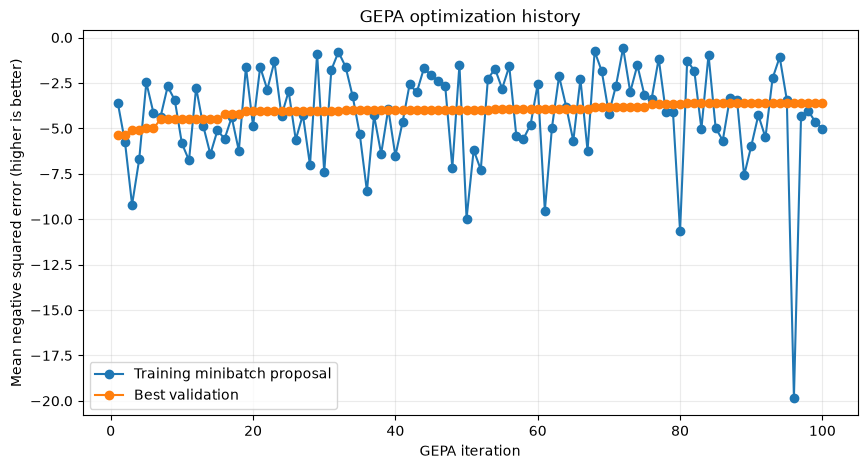

In [26]:
iterations = [row["iteration"] for row in optimization_history.rows]
train_metrics = [row["train_metric"] for row in optimization_history.rows]
validation_metrics = [row["validation_metric"] for row in optimization_history.rows]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(iterations, train_metrics, marker="o", label="Training minibatch proposal")
ax.plot(iterations, validation_metrics, marker="o", label="Best validation")
ax.set(
    xlabel="GEPA iteration",
    ylabel="Mean negative squared error (higher is better)",
    title="GEPA optimization history",
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()


### Save and display the result

Persist the winning candidate and the full GEPA result, then show the useful summary.


In [29]:
best_instructions, best_rubric, best_rubric_json = candidate_parts(
    result.best_candidate
)
best_validation_rmse = np.sqrt(
    max(0.0, -result.val_aggregate_scores[result.best_idx])
)

Path("optimized_jev_candidate.json").write_text(
    json.dumps(
        {"instructions": best_instructions, "criteria": best_rubric},
        indent=2,
        ensure_ascii=False,
    )
    + "\n",
    encoding="utf-8",
)
Path("gepa_jev_result.json").write_text(
    json.dumps(result.to_dict(), indent=2, default=str),
    encoding="utf-8",
)

print(f"proposal iterations: {GEPA_ITERATIONS}")
print(f"candidates explored: {result.num_candidates}")
print(f"GEPA evaluator calls: {result.total_metric_calls}")
print(f"best validation RMSE: {best_validation_rmse:.3f}")
print(f"\nOptimized Jev question:\n\n{best_instructions}")
print("\nOptimized ten-level rubric:\n")
for index, level in enumerate(best_rubric):
    print(f"{index}. {level}")


proposal iterations: 100
candidates explored: 69
GEPA evaluator calls: 19492
best validation RMSE: 1.904

Optimized Jev question:

What exact integer score from 80 to 100 did the critic most likely award this wine, judging the note’s overall level of endorsement and any stated flaws or limits, with balance, depth, structure, finish, and aging potential considered more important than descriptive detail?

Optimized ten-level rubric:

0. Below 80 — Not Recommended: use only for clearly spoiled, undrinkable or seriously defective wine, such as severe oxidation, volatile acidity, dilution, burning alcohol, brutal bitterness or another fault that leaves essentially no pleasure.
1. 80–82 — Acceptable: technically drinkable but markedly unpleasant or unbalanced. Thin fruit, harsh alcohol, sourness, excessive sweetness, dead texture, aggressive oak or several major problems dominate the experience.
2. 83–84 — Good, lower tier: sound wine offering limited pleasure, usually plain, weak, short, ge

## Score the optimized question and rubric on the tutorial holdout

This repeats the exact baseline protocol for the optimized pair: answer all rows, learn one offset from all 1,200 development labels, then compute RMSE and Spearman once on the 800 held-out labels.

In [28]:
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    optimized_asked = np.array(
        list(
            pool.map(
                lambda note: predict_candidate_score(
                    TYPESAFE_MODEL,
                    note,
                    best_instructions,
                    best_rubric_json,
                ),
                NOTES,
            )
        )
    )

optimized_shift = float(SCORES[DEV].mean() - optimized_asked[DEV].mean())
optimized_test_predictions = optimized_asked[TEST] + optimized_shift
optimized_test_metrics = {
    "shift": optimized_shift,
    "rmse": rmse(SCORES[TEST], optimized_test_predictions),
    "spearman": spearman(SCORES[TEST], optimized_test_predictions),
}

print(f"{'arm':<46}{'RMSE':>7}{'spearman':>10}")
for label, metrics in (
    (f"seed question + rubric, shifted {shift:+.2f}", seed_test_metrics),
    (f"optimized question + rubric, shifted {optimized_shift:+.2f}", optimized_test_metrics),
):
    print(f"{label:<46}{metrics['rmse']:>7.3f}{metrics['spearman']:>10.3f}")


arm                                              RMSE  spearman
seed question + rubric, shifted -1.82           2.207     0.764
optimized question + rubric, shifted -1.61      1.933     0.762
